# M1 · LN-tuning baseline (reproducing LNCLIP-DF / GenD)

**Goal of M1:** reproduce the strongest parameter-efficient baseline on our data, and build the training and evaluation code that M2–M6 reuse. GBLA will be compared against this model.

**Everything in M1 is borrowed** (this is the baseline, not our method) from Yermakov, Čech, Matas, Fritz, *Deepfake Detection that Generalizes Across Benchmarks*, WACV 2026 (arXiv 2508.06248, code: github.com/yermandy/GenD):

- frozen CLIP ViT-L/14 (OpenAI weights); only the 50 LayerNorms and a linear head are trained (104,450 parameters)
- the head reads the **L2-normalized** CLS token
- loss = cross-entropy + 0.5 · uniformity + 0.1 · alignment (Wang & Isola, ICML 2020)
- Adam without weight decay, bf16, batch 128, cyclic cosine learning rate (1 warm-up epoch 1e-5 → 3e-4, cosine back to 1e-5, 10-epoch cycles), 2 cycles = 20 epochs
- augmentations: horizontal flip, affine, Gaussian blur, colour jitter, JPEG quality 40–100
- paired real/fake training data (every fake has its source real video in the training set)

**Protocol:** train on the FF++ c23 train split with real + Deepfakes, Face2Face, FaceSwap, NeuralTextures. **FaceShifter is never seen in training** and is the unseen-generator test, exactly as in the paper. This is also one fold of our leave-one-generator-out protocol: changing `TRAIN_GENERATORS` in 1.1 gives the other folds.

**Known differences from the paper**, so numbers should be close but not identical:

| | paper | ours |
|---|---|---|
| face crops | RetinaFace + landmark alignment, 256 px | MTCNN box without alignment, 224 px |
| monitoring / model selection | external validation mix (CDFv2, DeepSpeak, FFIW) | FF++ val (we don't have those datasets) |
| seeds | mean of 5 | 1 (more later if needed) |
| slerp augmentation | in arXiv v1, not in final GenD code | not used |

**Reference numbers** (video-level AUROC %, paper arXiv v1, Table 3, LNCLIP-DF): FF 98.0 · DF 99.6 · F2F 98.2 · FS 98.6 · NT 95.7 · FaceShifter 88.2. Ablation Table 5, LN + L2 + uniformity/alignment (this recipe, no slerp): FaceShifter 87.3.

| Section | What it does | Run time |
|---|---|---|
| 1. Setup | settings, imports | seconds |
| 2. Data | integrity checks on the M0 crops, data loaders | ~2 min |
| 3. Model | build the detector, full parameter report | ~1 min |
| 4. Training | speed test, then resumable training | ~2–3 h (estimate printed in 4.2) |
| 5. Evaluation | test AUC per generator, FaceShifter = unseen, curves | ~5 min |
| 6. Send results back | push this notebook | – |

Nothing is installed in M1: everything was installed in M0.

## 1. Setup

### 1.1 Settings

`DATA_ROOT` must be the same folder as in M0 (crops and index are read from there). Each training run writes to its own folder `RUN_DIR` (checkpoints, history, predictions). Settings that change the result are stored in `RUN_DIR/config.json`; if you change any of them, also change `RUN_NAME`, otherwise 4.3 refuses to mix the two runs.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")   # same as M0
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"

# protocol
ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]   # FaceShifter = unseen
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}

# model (GenD recipe)
ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True            # head reads the L2-normalized CLS token
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True

# optimisation
BATCH_SIZE = 128
EPOCHS = 20               # 2 cycles
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0

# speed only (do not change results)
GRAD_CHECKPOINTING = False   # 4.2 switches it on automatically if the GPU runs out of memory
EVAL_BATCH = 256
NUM_WORKERS = min(16, os.cpu_count() or 4)

RUN_NAME = f"lnclip_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}"
RUN_DIR = RUNS_ROOT / "m1" / RUN_NAME

CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True,
    "train_generators": TRAIN_GENERATORS, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "lr_max": LR_MAX, "lr_min": LR_MIN, "seed": SEED,
}
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV} (run M0 first)"
print("run folder:", RUN_DIR)

run folder: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m1/lnclip_ViT-L-14_train-DF-F2F-FS-NT_seed0


### 1.2 Imports and environment

In [2]:
# 1.2 Imports and environment
import json, math, random, time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M1 needs the GPU"
DEVICE = "cuda"

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores": os.cpu_count(),
    "data loader workers": NUM_WORKERS,
    "JPEG augmentation available": hasattr(T, "JPEG"),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores,256
data loader workers,16
JPEG augmentation available,True


## 2. Data

### 2.1 Integrity checks on the M0 crops

M0 section 2.2 showed that the folders in `frames_all` are **scrambled**: e.g. `original/000` contains frames of other videos, and the five fakes of `000_003` show three different scenes. The M0 smoke-test crops were nevertheless correct, which means the crops were made from the videos. Before training on 192,000 crops we verify this on the data itself:

1. **Box source:** every original's face boxes should have been made with `FRAME_SOURCE = "videos"`.
2. **Pairing test:** a fake crop and its paired real crop show the same scene (same background, pose, framing; only the face is manipulated), so they should be far more similar than the fake and a random real crop. Expected: the paired difference is much smaller, and the paired crop is the closer one for ~100% of the 600 sampled fakes in every generator.
3. **Visual check:** 4 random test videos, the same frame from the original and its 5 fakes. Each row must show one scene.

**If check 2 is clearly below 100% for any generator, or a row in the figure mixes scenes, stop and push the notebook.** Training on mismatched pairs would silently corrupt every later result.

index: 192,000 crops


split,train,val,test
generator,,,
original,23040,4480,4480
Deepfakes,23040,4480,4480
Face2Face,23040,4480,4480
FaceSwap,23040,4480,4480
NeuralTextures,23040,4480,4480
FaceShifter,23040,4480,4480


face boxes by frame source: {'frames': 1002} (expected: all 'videos')


,samples,median_paired_diff,median_random_diff,pct_paired_closer
generator,,,,
Deepfakes,118,4.85,54.630001,100.00
Face2Face,101,15.88,57.430000,99.01
FaceShifter,136,4.80,55.820000,100.00
FaceSwap,125,7.80,55.529999,100.00
NeuralTextures,120,6.54,55.020000,100.00


PAIRING OK


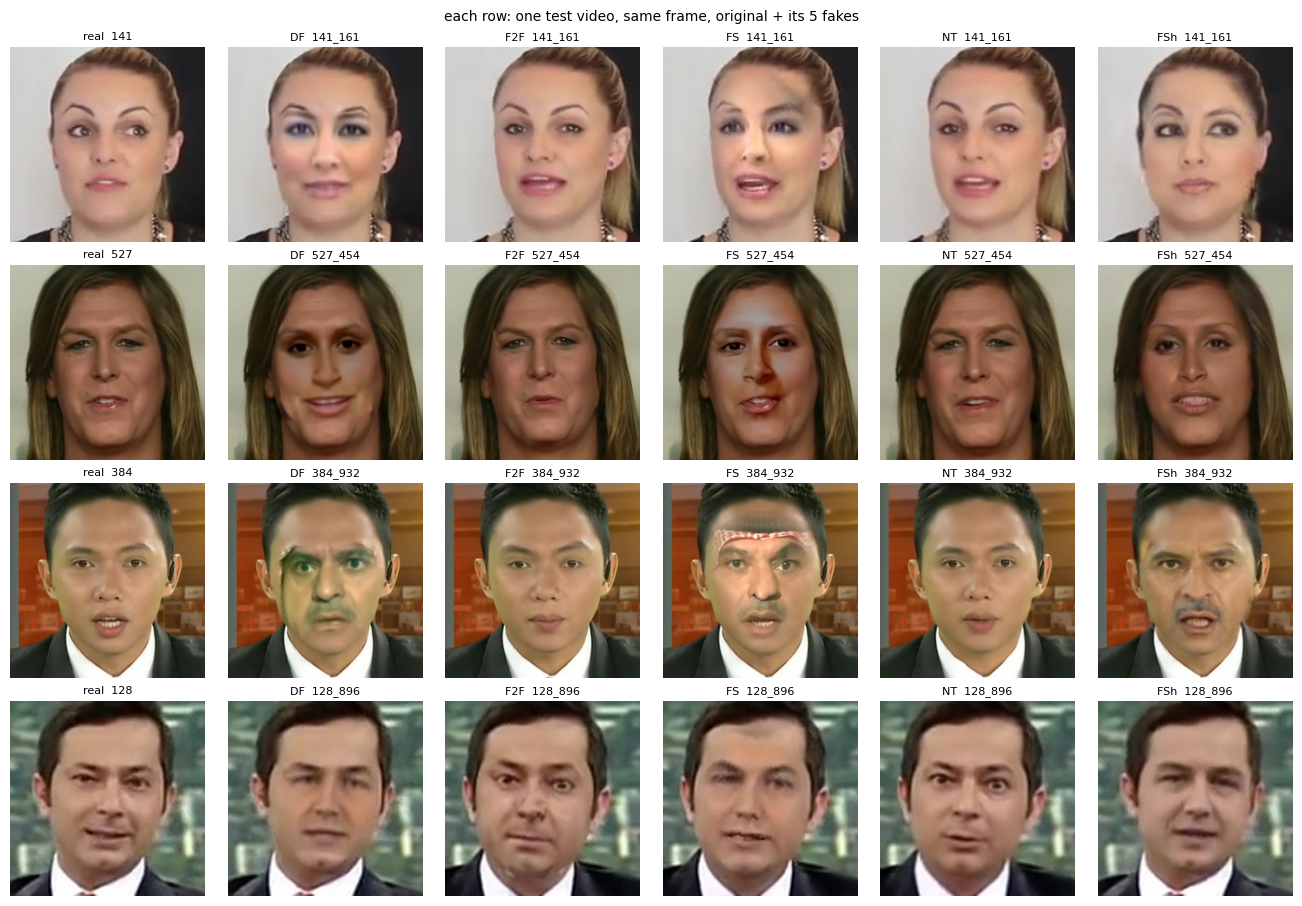

In [3]:
# 2.1 Integrity checks on the M0 crops
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
print(f"index: {len(index):,} crops")
display(index.groupby(["generator", "split"]).size().unstack().reindex(index=CATEGORIES, columns=["train", "val", "test"]))

# 1. box source
box_sources = Counter(json.loads(p.read_text()).get("source", "not recorded")
                      for p in (FACES_ROOT / "_boxes").glob("*.json"))
print("face boxes by frame source:", dict(box_sources), "(expected: all 'videos')")

# 2. pairing test
rng = np.random.default_rng(SEED)


def small_gray(rel_path):
    return np.asarray(Image.open(FACES_ROOT / rel_path).convert("L").resize((64, 64)), dtype=np.float32)


real_test = index[(index.split == "test") & (index.label == 0)].reset_index(drop=True)
fake_test = index[(index.split == "test") & (index.label == 1)].reset_index(drop=True)
rows = []
for r in fake_test.iloc[rng.choice(len(fake_test), 600, replace=False)].itertuples():
    other = real_test.iloc[rng.integers(len(real_test))]
    while other.target_id == r.target_id:
        other = real_test.iloc[rng.integers(len(real_test))]
    fake = small_gray(r.path)
    rows.append({"generator": r.generator,
                 "paired diff": np.abs(fake - small_gray(r.pair_path)).mean(),
                 "random diff": np.abs(fake - small_gray(other.path)).mean()})
pair_check = pd.DataFrame(rows)
pair_check["paired is closer"] = pair_check["paired diff"] < pair_check["random diff"]
summary = pair_check.groupby("generator").agg(
    samples=("paired diff", "size"),
    median_paired_diff=("paired diff", "median"),
    median_random_diff=("random diff", "median"),
    pct_paired_closer=("paired is closer", "mean"))
summary["pct_paired_closer"] *= 100
display(summary.round(2))
worst = summary.pct_paired_closer.min()
print("PAIRING OK" if worst >= 98 else f"PAIRING PROBLEM: only {worst:.1f}% for some generator -> stop and push the notebook")

# 3. visual check
targets = rng.choice(real_test.video_id.unique(), 4, replace=False)
fig, axes = plt.subplots(len(targets), len(CATEGORIES), figsize=(2.2 * len(CATEGORIES), 2.3 * len(targets)), squeeze=False)
for r, target in enumerate(targets):
    real_rows = real_test[real_test.video_id == target].sort_values("frame_idx")
    frame = real_rows.frame_idx.iloc[len(real_rows) // 2]
    for c, gen in enumerate(CATEGORIES):
        hit = index[(index.generator == gen) & (index.target_id == target) & (index.frame_idx == frame) & (index.split == "test")]
        ax = axes[r][c]
        if len(hit):
            ax.imshow(Image.open(FACES_ROOT / hit.path.iloc[0]))
            ax.set_title(f"{SHORT[gen]}  {hit.video_id.iloc[0]}", fontsize=8)
        ax.axis("off")
fig.suptitle("each row: one test video, same frame, original + its 5 fakes", fontsize=10)
plt.tight_layout()
plt.show()

### 2.2 Datasets and loaders

- **train**: train split, real + `TRAIN_GENERATORS` (115,200 crops for the default 4 generators). Real : fake = 1 : 4, as in the paper (no re-balancing; AUC is not affected by class ratio).
- **val**: val split, same generators. Used only to monitor training.
- **test**: test split, real + **all 5** generators, so FaceShifter is evaluated as unseen.

The training order of each epoch is fixed by `SEED` and the epoch number, so a resumed run sees exactly the same data order. The figure shows a few augmented training crops.

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 8, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


,train,val,test
generator,,,
original,23040,4480,4480
Deepfakes,23040,4480,4480
Face2Face,23040,4480,4480
FaceSwap,23040,4480,4480
NeuralTextures,23040,4480,4480
FaceShifter,0,0,4480


steps per epoch: 900


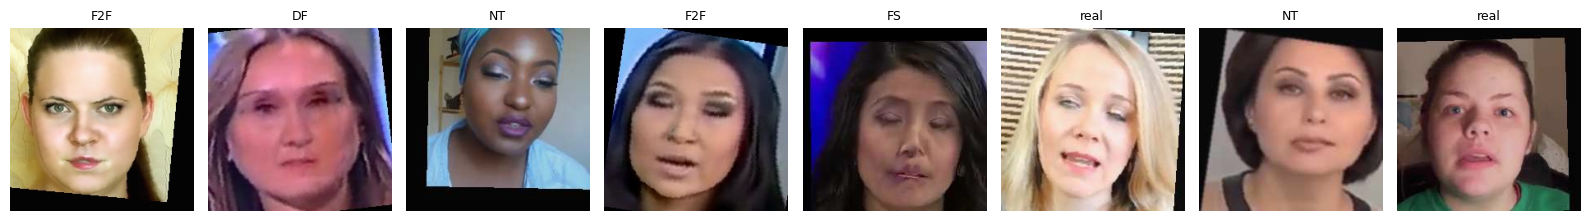

In [4]:
# 2.2 Datasets and loaders
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
        ]
        if hasattr(T, "JPEG"):
            steps.append(T.JPEG(quality=(40, 100)))
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    """Returns (image, label, generator code) for every row of an index slice."""

    def __init__(self, df, train):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = tv_tensors.Image(read_image(self.paths[i], mode=ImageReadMode.RGB))
        return self.transform(image).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class EpochSampler(Sampler):
    """Random order that depends only on (seed, epoch), so resumed runs see the same order."""

    def __init__(self, n, seed):
        self.n, self.seed, self.epoch = n, seed, 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        g = torch.Generator().manual_seed(self.seed * 100_003 + self.epoch)
        return iter(torch.randperm(self.n, generator=g).tolist())

    def __len__(self):
        return self.n


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_df = subset("val", TRAIN_GENERATORS)
test_df = subset("test", ALL_GENERATORS)

train_ds = FaceDataset(train_df, train=True)
train_sampler = EpochSampler(len(train_ds), SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]}).fillna(0).astype(int))
print(f"steps per epoch: {len(train_loader)}")

# a few augmented training crops
preview = [train_ds[i] for i in rng.choice(len(train_ds), 8, replace=False)]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, (x, y, g) in zip(axes, preview):
    img = (x * torch.tensor(CLIP_STD)[:, None, None] + torch.tensor(CLIP_MEAN)[:, None, None]).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(SHORT[CATEGORIES[g]], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Model

### 3.1 Build the detector

- CLIP ViT-L/14 visual encoder with OpenAI weights, loaded with **QuickGELU** activations (`force_quick_gelu=True`). The OpenAI weights were trained with QuickGELU; M0 loaded the model without it (the warning in M0 6.1), which doesn't change parameter counts but would give slightly wrong features.
- The output is the 1024-d CLS token after the final LayerNorm. CLIP's final projection to the text space (786,432 parameters) is not used and is removed.
- Everything is frozen except the 50 LayerNorms (scale and shift) and the linear head 1024 → 2.

In [5]:
# 3.1 Build the detector
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        z = F.normalize(feats, dim=-1)
        return self.head(z if L2_NORM else feats), z


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)
print("detector ready on", DEVICE)

detector ready on cuda


### 3.2 Parameter report

Total / trainable / frozen / trainable %, and the count per module type. Expected for ViT-L/14: trainable 104,450 = LayerNorm 102,400 + head 2,050, i.e. about 0.034% of the model.

In [6]:
# 3.2 Parameter report
def module_group(name):
    parts = name.split(".")
    if parts[0] == "head":
        return "linear head"
    if parts[-2].startswith("ln_"):
        return "LayerNorm"
    if "attn" in parts:
        return "attention"
    if "mlp" in parts:
        return "MLP"
    if "conv1" in parts:
        return "patch embedding"
    return "class + positional embedding"


rows = defaultdict(lambda: {"parameters": 0, "trainable": 0, "frozen": 0})
for name, p in model.named_parameters():
    g = rows[module_group(name)]
    g["parameters"] += p.numel()
    g["trainable" if p.requires_grad else "frozen"] += p.numel()
per_module = pd.DataFrame(rows).T.sort_values("parameters", ascending=False)
per_module.loc["TOTAL"] = per_module.sum()

total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_layernorms = sum(isinstance(m, nn.LayerNorm) for m in model.encoder.modules())
summary = pd.Series({
    "total": total,
    "trainable": trainable,
    "frozen": total - trainable,
    "trainable %": round(100 * trainable / total, 4),
    "LayerNorm modules": n_layernorms,
    "CLIP projection removed (not counted)": 786_432 if ARCH == "ViT-L-14" else "n/a",
}, name="value")
display(per_module.style.format("{:,}"))
display(summary.to_frame())
if ARCH == "ViT-L-14":
    assert trainable == 104_450 and n_layernorms == 50, "unexpected trainable set"

,parameters,trainable,frozen
MLP,"201,449,472",0,"201,449,472"
attention,"100,761,600",0,"100,761,600"
patch embedding,"602,112",0,"602,112"
class + positional embedding,"264,192",0,"264,192"
LayerNorm,"102,400","102,400",0
linear head,"2,050","2,050",0
TOTAL,"303,181,826","104,450","303,077,376"


,value
total,3.031818e+08
trainable,1.044500e+05
frozen,3.030774e+08
trainable %,3.450000e-02
LayerNorm modules,5.000000e+01
CLIP projection removed (not counted),7.864320e+05


## 4. Training

### 4.1 Loss, learning-rate schedule, evaluation and checkpoint helpers

- **Loss** (same definitions as the authors' code): cross-entropy on the logits; *alignment* = mean squared distance between L2-normalized features of same-label pairs in the batch; *uniformity* = log of the mean of exp(−2 · squared distance) over all pairs.
- **Learning rate**: a function of the global step only (cycles of 10 epochs: 1 epoch linear warm-up 1e-5 → 3e-4, then cosine down to 1e-5), so resuming needs no scheduler state.
- **Metrics**: AUC from ranks (Mann–Whitney), at frame level and at video level (mean fake probability over the video's 32 frames, as in the paper), plus video accuracy at threshold 0.5. Each generator is scored against the same real test videos.
- **Checkpoints** hold only the trainable parameters (104,450 numbers, ~0.4 MB) plus the optimizer state, written atomically.

In [7]:
# 4.1 Helpers
def compute_loss(logits, z, y):
    """Returns (total loss, dict of loss parts, per-sample cross-entropy)."""
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=z.device)
    d2 = (2 - 2 * (z @ z.T)[i, j]).clamp(min=0)          # squared distance of unit vectors
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def make_optimizer():
    params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.AdamW(params, lr=LR_MIN, betas=(0.9, 0.999), weight_decay=0.0)


def train_step(optimizer, x, y, lr):
    for group in optimizer.param_groups:
        group["lr"] = lr
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits, z = model(x)
    loss, parts, ce_each = compute_loss(logits.float(), z.float(), y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    return parts, ce_each


@torch.no_grad()
def predict(df):
    """Fake probability for every crop of an index slice."""
    loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
    model.eval()
    probs = []
    for x, _, _ in tqdm(loader, desc="predict", leave=False):
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, _ = model(x.to(DEVICE, non_blocking=True))
        probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    """AUC per test set: all seen generators together, then each generator alone (vs. the same reals)."""
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
            "frame AUC": 100 * auc(sub.label, sub.prob),
            "video AUC": 100 * auc(vid.label, vid.prob),
            "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean()),
            "real / fake videos": f"{(vid.label == 0).sum()} / {(vid.label == 1).sum()}",
        })
    return pd.DataFrame(rows).round(2)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}


def load_trainable(state):
    params = dict(model.named_parameters())
    for n, v in state.items():
        params[n].data.copy_(v.to(params[n].device))


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)

### 4.2 Speed test (does not change the model)

Runs a few training steps to measure GPU speed, data-loading speed and peak GPU memory, then restores the untouched weights. If the GPU runs out of memory it switches on gradient checkpointing (slower, much less memory) and measures again. The printed estimate tells you how long 4.3 will take; if it is longer than your C-DAC session, that's fine: 4.3 resumes.

In [8]:
# 4.2 Speed test (does not change the model)
saved = trainable_state()
speed_opt = make_optimizer()

batches_iter = iter(train_loader)
batches = [next(batches_iter) for _ in range(4)]           # workers warm up
t0 = time.time()
batches += [next(batches_iter) for _ in range(12)]
load_rate = 12 * BATCH_SIZE / (time.time() - t0)
del batches_iter


def timed_steps(n):
    torch.cuda.synchronize()
    t = time.time()
    for k in range(n):
        x, y, _ = batches[k % len(batches)]
        parts, _ = train_step(speed_opt, x.to(DEVICE), y.to(DEVICE), LR_MIN)
    torch.cuda.synchronize()
    return n * BATCH_SIZE / (time.time() - t), parts


torch.cuda.reset_peak_memory_stats()
try:
    timed_steps(2)
    gpu_rate, parts = timed_steps(10)
except torch.cuda.OutOfMemoryError:
    print("out of GPU memory -> switching on gradient checkpointing")
    speed_opt.zero_grad(set_to_none=True)
    torch.cuda.empty_cache()
    GRAD_CHECKPOINTING = True
    model.encoder.set_grad_checkpointing(True)
    torch.cuda.reset_peak_memory_stats()
    timed_steps(2)
    gpu_rate, parts = timed_steps(10)

peak_gb = torch.cuda.max_memory_allocated() / 1e9
load_trainable(saved)
del speed_opt, saved, batches
torch.cuda.empty_cache()

rate = min(gpu_rate, load_rate)
epoch_minutes = len(train_loader) * BATCH_SIZE / rate / 60 + len(val_df) / (4 * rate) / 60
pd.Series({
    "GPU training speed (img/s)": round(gpu_rate),
    "data loading speed (img/s)": round(load_rate),
    "bottleneck": "GPU" if gpu_rate < load_rate else "data loading",
    "peak GPU memory (GB)": round(peak_gb, 1),
    "gradient checkpointing": GRAD_CHECKPOINTING,
    "loss parts at last test step": {k: round(v, 3) for k, v in parts.items()},
    "estimated minutes per epoch": round(epoch_minutes, 1),
    f"estimated hours for {EPOCHS} epochs": round(EPOCHS * epoch_minutes / 60, 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 8, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


,value
GPU training speed (img/s),253
data loading speed (img/s),1668596
bottleneck,GPU
peak GPU memory (GB),28.9
gradient checkpointing,False
loss parts at last test step,"{'loss': -0.26, 'ce': 0.697, 'align': 1.092, '..."
estimated minutes per epoch,8.0
estimated hours for 20 epochs,2.7


### 4.3 Training (resumable)

After every epoch: FF++ val AUC is measured, and `epoch_XX.pt` (trainable weights) and `last.pt` (weights + optimizer + history) are saved to `RUN_DIR`.

- **Resuming** (after a crash, a timeout, or days later): run 1.1, 1.2, 2.1, 2.2, 3.1, 4.1 and this cell (skip 4.2 if you like). It continues after the last finished epoch with the same data order and learning rate; at most the interrupted epoch is repeated. If training already finished, this cell only shows the history.
- You can stop it at any time (Kernel → Interrupt).
- `CE real / DF / ...` columns are the training cross-entropy per generator. They show which generators are "easy" for the shared model, which is the generator-dominance question GBLA is about (E1 in M3).
- FF++ val AUC tends to saturate near 100% quickly (the paper reports the same); it is a sanity check, not a measure of generalization.

In [9]:
# 4.3 Training (resumable)
RUN_DIR.mkdir(parents=True, exist_ok=True)
config_path = RUN_DIR / "config.json"
if config_path.exists():
    assert json.loads(config_path.read_text()) == CONFIG, \
        f"{RUN_DIR} holds a run with different settings: restore them or change RUN_NAME"
else:
    config_path.write_text(json.dumps(CONFIG, indent=1))

optimizer = make_optimizer()
history, start_epoch = [], 0
if (RUN_DIR / "last.pt").exists():
    ckpt = load(RUN_DIR / "last.pt")
    load_trainable(ckpt["trainable"])
    optimizer.load_state_dict(ckpt["optimizer"])
    history, start_epoch = ckpt["history"], ckpt["epoch"]
    print(f"resuming: {start_epoch}/{EPOCHS} epochs already done")

steps_per_epoch = len(train_loader)
for epoch in range(start_epoch, EPOCHS):
    train_sampler.set_epoch(epoch)
    model.train()
    sums, n_steps, t0 = defaultdict(float), 0, time.time()
    ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
    ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
    for i, (x, y, g) in enumerate(tqdm(train_loader, desc=f"epoch {epoch + 1}/{EPOCHS}", leave=False)):
        lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch)
        x, y, g = (t.to(DEVICE, non_blocking=True) for t in (x, y, g))
        parts, ce_each = train_step(optimizer, x, y, lr)
        for k, v in parts.items():
            sums[k] += v
        ce_sum += torch.bincount(g, weights=ce_each, minlength=len(CATEGORIES))
        ce_cnt += torch.bincount(g, minlength=len(CATEGORIES))
        n_steps += 1

    val_table = metrics_table(predict(val_df))
    row = {"epoch": epoch + 1, "lr (end)": float(lr)}
    row.update({k: v / n_steps for k, v in sums.items()})
    row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k]) for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
    row.update({"val frame AUC": float(val_table["frame AUC"].iloc[0]),
                "val video AUC": float(val_table["video AUC"].iloc[0]),
                "minutes": (time.time() - t0) / 60})
    history.append(row)

    save_atomic(trainable_state(), RUN_DIR / f"epoch_{epoch + 1:02d}.pt")
    save_atomic({"epoch": epoch + 1, "trainable": trainable_state(), "optimizer": optimizer.state_dict(),
                 "history": history}, RUN_DIR / "last.pt")
    print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

pd.DataFrame(history).round(4)

resuming: 20/20 epochs already done


,epoch,lr (end),loss,ce,align,uniform,CE real,CE DF,CE F2F,CE FS,CE NT,val frame AUC,val video AUC,minutes
0,1,0.0003,-0.8528,0.5679,1.6025,-3.1619,0.9160,0.4474,0.5010,0.4577,0.5177,83.08,85.44,18.4745
1,2,0.0003,-1.3568,0.3791,1.9278,-3.8574,0.8456,0.1319,0.2816,0.1633,0.4731,92.83,95.87,18.4942
2,3,0.0003,-1.4679,0.2906,1.9427,-3.9056,0.6631,0.0708,0.1913,0.1100,0.4180,94.69,97.23,18.4762
3,4,0.0002,-1.5154,0.2518,1.9501,-3.9245,0.5889,0.0525,0.1524,0.0875,0.3778,95.56,97.83,18.5660
4,5,0.0002,-1.5408,0.2312,1.9555,-3.9351,0.5506,0.0438,0.1385,0.0773,0.3457,95.69,97.84,18.8219
5,6,0.0001,-1.5595,0.2154,1.9586,-3.9416,0.5167,0.0379,0.1242,0.0709,0.3276,95.90,98.00,19.4657
6,7,0.0001,-1.5699,0.2071,1.9613,-3.9463,0.5025,0.0354,0.1116,0.0659,0.3202,96.03,98.07,19.1441
7,8,0.0000,-1.5781,0.2000,1.9624,-3.9486,0.4860,0.0331,0.1082,0.0633,0.3091,95.93,97.97,18.2064
8,9,0.0000,-1.5816,0.1971,1.9629,-3.9499,0.4796,0.0311,0.1079,0.0619,0.3050,95.94,97.95,18.0646
9,10,0.0000,-1.5834,0.1955,1.9632,-3.9503,0.4777,0.0311,0.1069,0.0605,0.3013,95.94,97.95,18.1314


## 5. Evaluation

### 5.1 Test results

The **main result is the final epoch** (a fixed training budget, as in the paper). For reference we also score the epoch with the best FF++ val AUC; we do not select by FaceShifter, because FaceShifter must stay unseen.

Test sets: each generator's test fakes against the same 140 real test videos (4,480 real crops). `UNSEEN` marks generators not used in training. All test predictions are saved to `RUN_DIR` for later analysis. Needs 1.1–4.1 (not 4.2/4.3 if training is already finished).

In [10]:
# 5.1 Test results
ckpt = load(RUN_DIR / "last.pt")
assert ckpt["epoch"] == EPOCHS, f"training not finished: {ckpt['epoch']}/{EPOCHS} epochs (run 4.3)"
history = ckpt["history"]
hist = pd.DataFrame(history)
best_epoch = int(hist.loc[hist["val video AUC"].idxmax(), "epoch"])

results = {}
for label, epoch in [("final", EPOCHS), ("best FF++ val", best_epoch)]:
    if label != "final" and epoch == EPOCHS:
        print(f"best FF++ val epoch = final epoch ({EPOCHS})")
        continue
    load_trainable(load(RUN_DIR / f"epoch_{epoch:02d}.pt"))
    pred = predict(test_df)
    pred.to_csv(RUN_DIR / f"test_predictions_epoch{epoch:02d}.csv", index=False)
    table = metrics_table(pred)
    results[f"{label} (epoch {epoch})"] = table
    print(f"\n=== {label}: epoch {epoch} ===")
    display(table)
load_trainable(load(RUN_DIR / f"epoch_{EPOCHS:02d}.pt"))      # leave the final model loaded

# comparison with the paper (only meaningful for the paper's protocol)
PAPER_VIDEO_AUC = {"Deepfakes": 99.6, "Face2Face": 98.2, "FaceSwap": 98.6, "NeuralTextures": 95.7, "FaceShifter": 88.2}
if TRAIN_GENERATORS == ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]:
    final = results[f"final (epoch {EPOCHS})"].set_index("test set")
    comparison = pd.DataFrame({
        "ours, video AUC": [final.loc["seen combined (DF+F2F+FS+NT)", "video AUC"]] + [final.loc[g, "video AUC"] for g in PAPER_VIDEO_AUC],
        "paper LNCLIP-DF, video AUC": [98.0] + list(PAPER_VIDEO_AUC.values()),
    }, index=["FF (seen combined)"] + list(PAPER_VIDEO_AUC))
    comparison["difference"] = comparison.iloc[:, 0] - comparison.iloc[:, 1]
    print("\n=== comparison with the paper (arXiv v1, Table 3; their FaceShifter without slerp: 87.3) ===")
    display(comparison.round(2))

(RUN_DIR / "results.json").write_text(json.dumps(
    {k: v.to_dict(orient="records") for k, v in results.items()} | {"config": CONFIG, "best_val_epoch": best_epoch},
    indent=1))

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 8, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
                                                          


=== final: epoch 20 ===


,test set,status,frame AUC,video AUC,video acc @0.5,real / fake videos
0,seen combined (DF+F2F+FS+NT),seen,96.36,98.04,93.57,140 / 560
1,Deepfakes,seen,98.40,99.39,95.71,140 / 140
2,Face2Face,seen,96.78,98.40,93.21,140 / 140
3,FaceSwap,seen,98.54,99.38,95.71,140 / 140
4,NeuralTextures,seen,91.71,94.98,88.57,140 / 140
5,FaceShifter,UNSEEN,81.98,88.37,73.57,140 / 140


/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 8, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
                                                          


=== best FF++ val: epoch 7 ===


,test set,status,frame AUC,video AUC,video acc @0.5,real / fake videos
0,seen combined (DF+F2F+FS+NT),seen,95.77,97.67,93.43,140 / 560
1,Deepfakes,seen,98.25,99.29,96.07,140 / 140
2,Face2Face,seen,96.15,98.12,93.57,140 / 140
3,FaceSwap,seen,98.15,99.20,96.07,140 / 140
4,NeuralTextures,seen,90.50,94.06,88.21,140 / 140
5,FaceShifter,UNSEEN,81.37,88.37,76.43,140 / 140



=== comparison with the paper (arXiv v1, Table 3; their FaceShifter without slerp: 87.3) ===


,"ours, video AUC","paper LNCLIP-DF, video AUC",difference
FF (seen combined),98.04,98.0,0.04
Deepfakes,99.39,99.6,-0.21
Face2Face,98.40,98.2,0.20
FaceSwap,99.38,98.6,0.78
NeuralTextures,94.98,95.7,-0.72
FaceShifter,88.37,88.2,0.17


2552

### 5.2 Training curves

Left: loss parts. Middle: training cross-entropy per generator (lower = easier for the shared model; a large spread is the first hint of generator dominance). Right: FF++ val AUC and the learning rate.

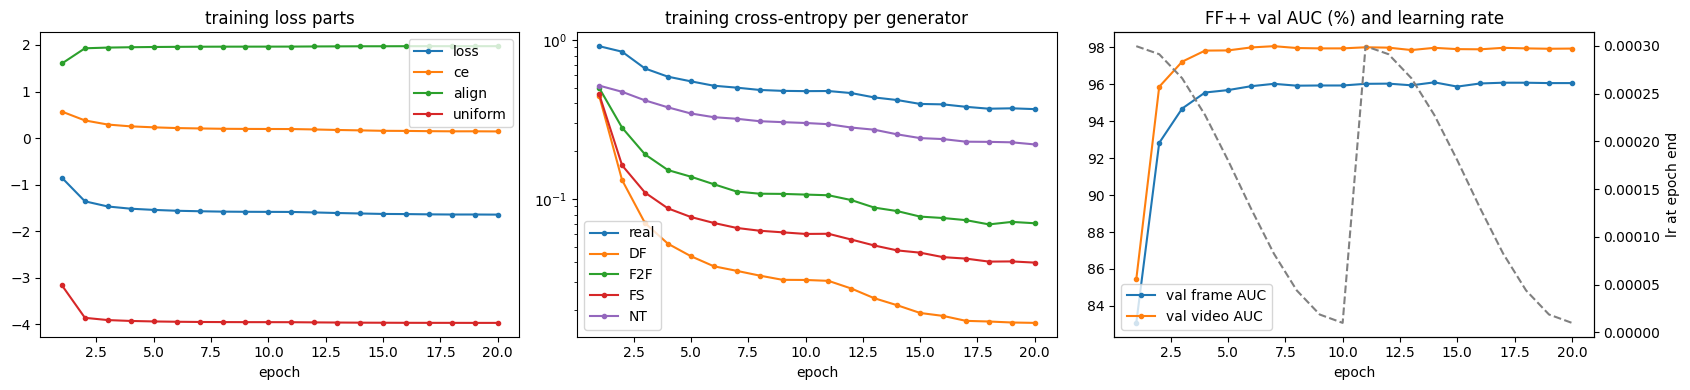

final training cross-entropy per generator:


,CE
CE real,0.3682
CE DF,0.0167
CE F2F,0.0706
CE FS,0.0399
CE NT,0.2208


In [11]:
# 5.2 Training curves
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for k in ["loss", "ce", "align", "uniform"]:
    axes[0].plot(hist.epoch, hist[k], marker=".", label=k)
axes[0].set_title("training loss parts")
axes[0].legend()

for c in [c for c in hist.columns if c.startswith("CE ")]:
    axes[1].plot(hist.epoch, hist[c], marker=".", label=c[3:])
axes[1].set_yscale("log")
axes[1].set_title("training cross-entropy per generator")
axes[1].legend()

axes[2].plot(hist.epoch, hist["val frame AUC"], marker=".", label="val frame AUC")
axes[2].plot(hist.epoch, hist["val video AUC"], marker=".", label="val video AUC")
axes[2].set_title("FF++ val AUC (%) and learning rate")
axes[2].legend(loc="lower left")
lr_axis = axes[2].twinx()
lr_axis.plot(hist.epoch, hist["lr (end)"], color="gray", linestyle="--")
lr_axis.set_ylabel("lr at epoch end")
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.show()

print("final training cross-entropy per generator:")
display(hist[[c for c in hist.columns if c.startswith("CE ")]].iloc[-1].to_frame("CE").round(4))

## 6. Send results back

1. Save this notebook (Ctrl+S) with its outputs.
2. From the repository folder on C-DAC:

```bash
git pull
git add M1.ipynb
git commit -m "M1 run outputs"
git push
```

When git asks for a password, paste your GitHub token. Do not put the token in this notebook or any file, and do not send it to me. Only `M1.ipynb` is committed; checkpoints and predictions stay in `RUN_DIR` on C-DAC.

**What I need from the outputs:** the integrity checks (2.1), the loader table (2.2), the parameter report (3.2), the speed test (4.2), the training history (4.3), the test tables and the paper comparison (5.1), and the curves (5.2).

**Suggested order:** run 1.1 → 4.2 first (about 5 minutes) and check that 2.1 says `PAIRING OK`. Then run 4.3 (hours, resumable), then section 5.

**What M1 hands to the next milestones:** the training/evaluation code; the trained LN-tuning model and its per-epoch checkpoints (the pooled-ERM solution that E1 analyses); per-generator training losses; and the baseline numbers GBLA has to beat on the unseen generator.